# Flight Fare Prediction Using Machine Learning

#### Project Title : Flight Fare Prediction Using Machine Learning

The primary objective of this project is to develop a machine learning model that can accurately predict 
flight ticket prices based on various factors such as airline,source,destination,journey date,departure time,etc...

In [1]:
!pip install xgboost lightgbm catboost

## Importing Requried Libraries

In [2]:
# Main objective is to understand more about data
# Import Requried Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings;
warnings.filterwarnings('ignore')

### Loading the Dataset

In [3]:
# Load the Dataset
df = pd.read_excel('Flight_Fare.xlsx')

# Display first five rows
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


### Understanding the Dataset

Here, we understand the structure of the dataset by checking dimensions, data types, and missing values

In [4]:
# Understanding the Dataset

print(df.shape)
print(df.info())

(10683, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB
None


In [5]:
# Understanding the Dataset
print(df.describe)
print(df.isnull().sum())

<bound method NDFrame.describe of            Airline Date_of_Journey    Source Destination  \
0           IndiGo      24/03/2019  Banglore   New Delhi   
1        Air India       1/05/2019   Kolkata    Banglore   
2      Jet Airways       9/06/2019     Delhi      Cochin   
3           IndiGo      12/05/2019   Kolkata    Banglore   
4           IndiGo      01/03/2019  Banglore   New Delhi   
...            ...             ...       ...         ...   
10678     Air Asia       9/04/2019   Kolkata    Banglore   
10679    Air India      27/04/2019   Kolkata    Banglore   
10680  Jet Airways      27/04/2019  Banglore       Delhi   
10681      Vistara      01/03/2019  Banglore   New Delhi   
10682    Air India       9/05/2019     Delhi      Cochin   

                       Route Dep_Time  Arrival_Time Duration Total_Stops  \
0                  BLR → DEL    22:20  01:10 22 Mar   2h 50m    non-stop   
1      CCU → IXR → BBI → BLR    05:50         13:15   7h 25m     2 stops   
2      DEL → LKO 

##### We have check the dataset of Flight Fare Prediction. Since we have to clean the data.

## Data Cleaning 

Here, we handle missing values and prepare the dataset for further analysis and model building.

In [6]:
# Data Cleaning
# Removing missing values from the dataset

df.dropna(inplace = True)
print(df.isnull().sum())
print(df.shape)

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64
(10682, 11)


#### Since there is no missing values in datset

## Feature Engineering

In this step, we extract and transform important features from date and time variables to create
meaningful inputs for the machine learning model. Feature engineering plays a crucial role in enchancing 
model performance and improving prediction accuracy.

In [7]:
# Feature Engineeering

df['Journey_day'] = pd.to_datetime(df["Date_of_Journey"]).dt.day
df['Journey_month'] = pd.to_datetime(df["Date_of_Journey"]).dt.month

df['Deep_hour'] = pd.to_datetime(df["Dep_Time"]).dt.hour
df['Deep_min'] = pd.to_datetime(df["Dep_Time"]).dt.minute

df.drop(['Date_of_Journey', 'Dep_Time'], axis = 1, inplace = True)

In [8]:
# Displaying the first five rows 
df.head()

,Airline,Source,Destination,Route,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Deep_hour,Deep_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,22,20
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,13:15,7h 25m,2 stops,No info,7662,1,5,5,50
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,04:25 10 Jun,19h,2 stops,No info,13882,9,6,9,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,23:30,5h 25m,1 stop,No info,6218,12,5,18,5
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,21:35,4h 45m,1 stop,No info,13302,1,3,16,50


## Processing Duration and Time Features

Here, we convert the duration information into numerical values and preapring the time-related features for model training.

In [9]:
# Processing Duration

df["Duration"] = df["Duration"].astype(str)
df["Duration_hours"] = df["Duration"].str.extract('(\d+)h').fillna(0)
df["Duration_mins"] = df["Duration"].str.extract('(\d+)m').fillna(0)

df["Duration_hours"] = df["Duration_hours"].astype(int)
df["Duration_mins"] = df["Duration_mins"].astype(int)

df.drop("Duration", axis = 1, inplace = True)

In [10]:
df.head()

,Airline,Source,Destination,Route,Arrival_Time,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Deep_hour,Deep_min,Duration_hours,Duration_mins
0,IndiGo,Banglore,New Delhi,BLR → DEL,01:10 22 Mar,non-stop,No info,3897,24,3,22,20,2,50
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,13:15,2 stops,No info,7662,1,5,5,50,7,25
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,04:25 10 Jun,2 stops,No info,13882,9,6,9,25,19,0
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,23:30,1 stop,No info,6218,12,5,18,5,5,25
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,21:35,1 stop,No info,13302,1,3,16,50,4,45


## Exploratory Data Analysis(EDA)

In this step, we perform Exploratory Data Analysis to understand the distribution of 
Flight Prices and identify patterns and relationships in the dataset

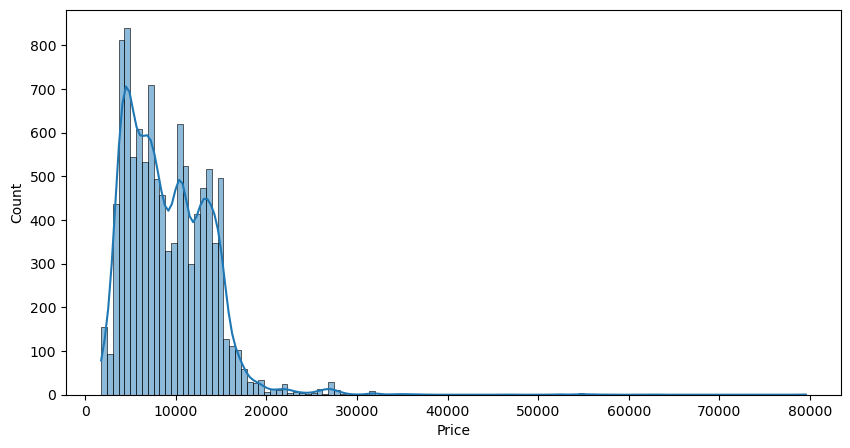

In [11]:
# Exploratory Data Analysis

plt.figure(figsize = (10,5))
sns.histplot(df["Price"], kde = True)
plt.show()

## Encoding Categorical Variables

In [12]:
# Encoding Categorical Features
df = pd.get_dummies(df,drop_first = True)

# Displaying first five rows
df.head()

,Price,Journey_day,Journey_month,Deep_hour,Deep_min,Duration_hours,Duration_mins,Airline_Air India,Airline_GoAir,Airline_IndiGo,...,Total_Stops_non-stop,Additional_Info_1 Short layover,Additional_Info_2 Long layover,Additional_Info_Business class,Additional_Info_Change airports,Additional_Info_In-flight meal not included,Additional_Info_No Info,Additional_Info_No check-in baggage included,Additional_Info_No info,Additional_Info_Red-eye flight
0,3897,24,3,22,20,2,50,False,False,True,...,True,False,False,False,False,False,False,False,True,False
1,7662,1,5,5,50,7,25,True,False,False,...,False,False,False,False,False,False,False,False,True,False
2,13882,9,6,9,25,19,0,False,False,False,...,False,False,False,False,False,False,False,False,True,False
3,6218,12,5,18,5,5,25,False,False,True,...,False,False,False,False,False,False,False,False,True,False
4,13302,1,3,16,50,4,45,False,False,True,...,False,False,False,False,False,False,False,False,True,False


In [19]:
# Remove special characters from column names
import re
df.columns = [re.sub(r'[^A-Za-z0-9_]','_',col) for col in df.columns]

## Train-Test Split

In this step, we divide the dataset into training and testing sets. The training datset is used to train the machine learning models, while testing 
dataset is used to evaluate their performance on unseen data.

In [20]:
# Train-Test Split

X = df.drop("Price", axis = 1)
Y = df["Price"]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)
print("Training Data Shape :", X_train.shape)
print("Training Data Shape :", Y_test.shape)

Training Data Shape : (8545, 1508)
Training Data Shape : (2137,)


## Train Models

#### Linear Regression Model

In this step, we train the Linear Regression model and evaluate its performance using MAE,RMSE,and R2 Score.

In [21]:
# Linear Regression

lr_model = LinearRegression()
lr_model.fit(X_train,Y_train)
lr_pred = lr_model.predict(X_test)

print("Linear Regression")
print("MAE :", mean_absolute_error(Y_test, lr_pred))
print("RMSE :", np.sqrt(mean_squared_error(Y_test, lr_pred)))
print("R2 Score :", r2_score(Y_test, lr_pred))

Linear Regression
MAE : 1277.5825930797043
RMSE : 2080.801513335506
R2 Score : 0.7991965667463932


#### Random Forest Regressor

In this step, we train the Random Forest Regressor model and evaluate its prediction performance.

In [22]:
# Random forest Regressor

rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, Y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest")
print("MAE :", mean_absolute_error(Y_test, rf_pred))
print("RMSE :", np.sqrt(mean_squared_error(Y_test, rf_pred)))
print("R2 Score :", r2_score(Y_test, rf_pred))

Random Forest
MAE : 600.199059770781
RMSE : 1626.4331835256996
R2 Score : 0.8773175962113912


#### XGBoost Regressor

In this step, we train the XGBoost Regressor model and evaluate itd prediction accuracy.

In [23]:
# XGBoost Regressor

xgb_model = XGBRegressor(random_state = 42)
xgb_model.fit(X_train, Y_train)
xgb_pred = xgb_model.predict(X_test)

print("XGBoost")
print("MAE :", mean_absolute_error(Y_test, xgb_pred))
print("RMSE :", np.sqrt(mean_squared_error(Y_test, xgb_pred)))
print("R2 score :", r2_score(Y_test, xgb_pred))

XGBoost
MAE : 833.813720703125
RMSE : 1424.4430490546122
R2 score : 0.9058977365493774


#### LightGBM Regressor

In this step, we train the LightGBM Regressor model and evaluate its performance.

In [24]:
# LightGBM Regressor

lgbm_model = LGBMRegressor(random_state = 42)
lgbm_model.fit(X_train, Y_train)
lgbm_pred = lgbm_model.predict(X_test)

print("LightGBM")
print("MAE :", mean_absolute_error(Y_test, lgbm_pred))
print("RMSE :", np.sqrt(mean_squared_error(Y_test, lgbm_pred)))
print("R2 Score :", r2_score(Y_test, lgbm_pred))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.024234 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 461
[LightGBM] [Info] Number of data points in the train set: 8545, number of used features: 184
[LightGBM] [Info] Start training from score 9078.336688
LightGBM
MAE : 883.0813640098697
RMSE : 1671.411020960777
R2 Score : 0.870438386812917


#### CatBoost Regressor

In this step, we train the CateBoost Regressor model and evaluate its prediction performance.

In [25]:
# CatBoost Regressor

cat_model = CatBoostRegressor(verbose = 0, random_state = 42)
cat_model.fit(X_train, Y_train)
cat_pred = cat_model.predict(X_test)

print("CatBoost")
print("MAE :", mean_absolute_error(Y_test, cat_pred))
print("RMSE :", np.sqrt(mean_squared_error(Y_test, cat_pred)))
print("R2 score :", r2_score(Y_test, cat_pred))

CatBoost
MAE : 898.8918208473342
RMSE : 1403.6005879406887
R2 score : 0.90863141340282


## Model Comparison

In this step, we compare the performance of all machine learning model using MAE,RMSE,and R2 Score to identify the best-performing model.

In [27]:
# Model Comparison

results = pd.DataFrame({"Model" : ["Linear Regression", "Random Forest", "XGBoost", "LightGBM", "CatBoost"],
                       "MAE":[
                           mean_absolute_error(Y_test, lr_pred),
                           mean_absolute_error(Y_test, rf_pred),
                           mean_absolute_error(Y_test, xgb_pred),
                           mean_absolute_error(Y_test, lgbm_pred),
                           mean_absolute_error(Y_test, cat_pred)
                       ],
                       "RMSE":[
                           np.sqrt(mean_squared_error(Y_test, lr_pred)),
                           np.sqrt(mean_squared_error(Y_test, rf_pred)),
                           np.sqrt(mean_squared_error(Y_test, xgb_pred)),
                           np.sqrt(mean_squared_error(Y_test, lgbm_pred)),
                           np.sqrt(mean_squared_error(Y_test, cat_pred))
                       ],
                        "R2 Score" :[
                            r2_score(Y_test, lr_pred),
                            r2_score(Y_test, rf_pred),
                            r2_score(Y_test, xgb_pred),
                            r2_score(Y_test, lgbm_pred),
                            r2_score(Y_test, cat_pred)
                        ]
})
results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1277.582593,2080.801513,0.799197
1,Random Forest,600.199060,1626.433184,0.877318
2,XGBoost,833.813721,1424.443049,0.905898
3,LightGBM,883.081364,1671.411021,0.870438
4,CatBoost,898.891821,1403.600588,0.908631


## Best Model Selection

In this step, we identify the best-performing machine learning model by comparing machine learning model by comparing the evaluation metrics.
The model with highest R2 Score and the lowest MAE and RMSE is selected for the final prediction.

In [28]:
# Best Model Selection

best_model = results.sort_values(by = "R2 Score", ascending = False)
print("best_model")

best_model


## Flight Fare Prediction

In this step, we use the best-performing model to predict the flight fare for a sample flight from the testing dataset.

In [33]:
# Flight Fare Prediction
sample_flight = X_test.iloc[[0]]
prediction= rf_model.predict(sample_flight)
print("Prediction Flight Fare :", prediction[0])

Prediction Flight Fare : 16627.62


## Final Conclusion